# Make shape files for example data

Data source is ONS (specific)

Pick out just the Devon bits
and merge districts in Devon based on LSOA names.

In [1]:
p = '~/samuel_book/geography_data/data_geojson/ons_data'
f = 'LSOA_Dec_2011_Boundaries_Generalised_Clipped_BGC_EW_V3.geojson'


In [2]:
import geopandas as gpd
import pandas as pd

In [3]:
gdf = gpd.read_file(f'{p}/{f}')

In [4]:
p1 = '~/samuel_book/geography_data/data_tabular/ons_data'
f1 = 'LSOA11_CCG21_STP21_LAD21_EN_LU.csv'
# p1 '~/ons_data'
# f1 = 'Regions_December_2022_EN_BGC_4589208765943883498.csv'

In [5]:
df = pd.read_csv(f'{p1}/{f1}')

In [6]:
df

,LSOA11CD,LSOA11NM,CCG21CD,CCG21CDH,CCG21NM,STP21CD,STP21NM,LAD21CD,LAD21NM,FID
0,E01012259,Stockton-on-Tees 010D,E38000247,16C,NHS Tees Valley CCG,E54000050,Cumbria and North East,E06000004,Stockton-on-Tees,1
1,E01012002,Hartlepool 006D,E38000247,16C,NHS Tees Valley CCG,E54000050,Cumbria and North East,E06000001,Hartlepool,2
2,E01012260,Stockton-on-Tees 007C,E38000247,16C,NHS Tees Valley CCG,E54000050,Cumbria and North East,E06000004,Stockton-on-Tees,3
3,E01012261,Stockton-on-Tees 007D,E38000247,16C,NHS Tees Valley CCG,E54000050,Cumbria and North East,E06000004,Stockton-on-Tees,4
4,E01012003,Hartlepool 014F,E38000247,16C,NHS Tees Valley CCG,E54000050,Cumbria and North East,E06000001,Hartlepool,5
...,...,...,...,...,...,...,...,...,...,...
32839,E01032513,Westminster 010G,E38000256,W2U3Z,NHS North West London CCG,E54000027,North West London Health and Care Partnership,E09000033,Westminster,32840
32840,E01033593,Westminster 015F,E38000256,W2U3Z,NHS North West London CCG,E54000027,North West London Health and Care Partnership,E09000033,Westminster,32841
32841,E01033594,Westminster 015G,E38000256,W2U3Z,NHS North West London CCG,E54000027,North West London Health and Care Partnership,E09000033,Westminster,32842
32842,E01033606,Westminster 014F,E38000256,W2U3Z,NHS North West London CCG,E54000027,North West London Health and Care Partnership,E09000033,Westminster,32843


In [7]:
df['LAD21NM'].unique()

array(['Stockton-on-Tees', 'Hartlepool', 'Middlesbrough',
       'Redcar and Cleveland', 'Darlington', 'Blackburn with Darwen',
       'Blackpool', 'Warrington', 'Halton', 'East Riding of Yorkshire',
       'Kingston upon Hull, City of', 'North East Lincolnshire',
       'North Lincolnshire', 'York', 'Derby', 'Nottingham', 'Leicester',
       'Rutland', 'Herefordshire, County of', 'Stoke-on-Trent',
       'Telford and Wrekin', 'Bath and North East Somerset',
       'Bristol, City of', 'North Somerset', 'South Gloucestershire',
       'Plymouth', 'Swindon', 'Torbay', 'Peterborough', 'Southend-on-Sea',
       'Thurrock', 'Luton', 'Medway', 'Reading', 'West Berkshire',
       'Bracknell Forest', 'Slough', 'Milton Keynes', 'Wokingham',
       'Windsor and Maidenhead', 'Brighton and Hove', 'Southampton',
       'Portsmouth', 'County Durham', 'Isle of Wight', 'Cheshire East',
       'Cheshire West and Chester', 'Shropshire', 'Cornwall', 'Wiltshire',
       'Isles of Scilly', 'Central Bedford

In [8]:
lads_devon = ['Plymouth', 'Torbay', 'East Devon', 'Mid Devon', 'Exeter', 'North Devon',
       'South Hams', 'Teignbridge', 'Torridge', 'West Devon', ]

In [9]:
df[df['LAD21NM'].isin(lads_devon)]

,LSOA11CD,LSOA11NM,CCG21CD,CCG21CDH,CCG21NM,STP21CD,STP21NM,LAD21CD,LAD21NM,FID
2854,E01015053,Plymouth 027A,E38000230,15N,NHS Devon CCG,E54000037,Devon,E06000026,Plymouth,2855
2863,E01015054,Plymouth 027B,E38000230,15N,NHS Devon CCG,E54000037,Devon,E06000026,Plymouth,2864
2869,E01015055,Plymouth 021A,E38000230,15N,NHS Devon CCG,E54000037,Devon,E06000026,Plymouth,2870
2871,E01015056,Plymouth 021B,E38000230,15N,NHS Devon CCG,E54000037,Devon,E06000026,Plymouth,2872
2874,E01015057,Plymouth 021C,E38000230,15N,NHS Devon CCG,E54000037,Devon,E06000026,Plymouth,2875
...,...,...,...,...,...,...,...,...,...,...
10395,E01020300,Torridge 002B,E38000230,15N,NHS Devon CCG,E54000037,Devon,E07000046,Torridge,10396
10396,E01020301,Torridge 009D,E38000230,15N,NHS Devon CCG,E54000037,Devon,E07000046,Torridge,10397
10397,E01020302,Torridge 008D,E38000230,15N,NHS Devon CCG,E54000037,Devon,E07000046,Torridge,10398
10398,E01020303,Torridge 007B,E38000230,15N,NHS Devon CCG,E54000037,Devon,E07000046,Torridge,10399


In [10]:
lsoa_devon = df.loc[df['LAD21NM'].isin(lads_devon), 'LSOA11CD'].values

<Axes: >

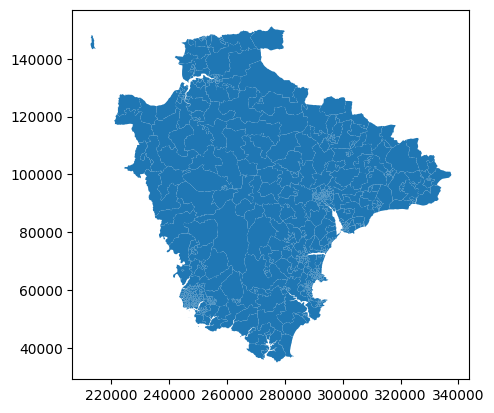

In [11]:
gdf.loc[gdf['LSOA11CD'].isin(lsoa_devon)].plot()

In [24]:
gdf_devon = gdf.loc[gdf['LSOA11CD'].isin(lsoa_devon)]

In [10]:
gdf_devon['geometry'] = gdf_devon['geometry'].set_precision(0.0001)

In [23]:
gdf_devon['geometry'].set_precision(0.0001)

0      POLYGON ((247893.675 60270.571, 247896.926 602...
1      POLYGON ((246946.495 60828.934, 246985.66 6080...
2      POLYGON ((249811.109 60386.617, 249770.766 603...
3      POLYGON ((246743.596 60285.209, 246756.523 602...
4      POLYGON ((248321.63 60341.83, 248445.823 60342...
                             ...                        
702    POLYGON ((296044.386 91620.299, 296027 91547, ...
703    POLYGON ((292270.096 95589.796, 292322.594 955...
704    POLYGON ((295661.516 90879.486, 295220.522 907...
705    MULTIPOLYGON (((295777.777 88110.188, 295843.9...
706    POLYGON ((297293.698 87969.998, 297344.9 88117...
Length: 707, dtype: geometry

In [20]:
gdf_devon.loc[0, ['geometry']]

geometry    POLYGON ((247801.375 60189.402, 247893.6753 60...
Name: 0, dtype: object

Use coordinate precision to make sure the precision is kept while saving the file. Otherwise, get way too many decimal places due to floating point shenanigans.

In [24]:
gdf_devon.to_file('data/lsoa2011_devon.geojson', layer_options={"COORDINATE_PRECISION": 4})

In [13]:
gdf_devon = gpd.read_file('lsoa2011_devon.geojson')

Save LSOA to district lookup:

In [16]:
gdf_devon['district_name'] = gdf_devon['LSOA11NM'].str.rsplit(' ', n=1, expand=True)[0]

In [18]:
gdf_devon[['LSOA11CD', 'district_name']].to_csv('lookup_lsoa2011_district_devon.csv', index=False)

In [27]:
gdf_devon

,FID,LSOA11CD,LSOA11NM,LSOA11NMW,BNG_E,BNG_N,LONG,LAT,GlobalID,area_name,geometry
0,14568,E01015023,Plymouth 003A,Plymouth 003A,247552,60231,-4.14743,50.42208,6e00dc30-ff9b-4373-a273-8f83ac4f0e43,Plymouth,"POLYGON ((247801.375 60189.402, 247893.675 602..."
1,14569,E01015024,Plymouth 004A,Plymouth 004A,246298,60366,-4.16512,50.42297,70bf14eb-d03d-425f-804c-8f8fb0266310,Plymouth,"POLYGON ((246716.109 60750.531, 246946.495 608..."
2,14570,E01015025,Plymouth 001A,Plymouth 001A,249392,60203,-4.12153,50.42231,05f33914-7f44-48a6-aef2-983de4417eab,Plymouth,"POLYGON ((249720.786 60435.671, 249811.109 603..."
3,14571,E01015026,Plymouth 003B,Plymouth 003B,246634,60074,-4.16028,50.42043,06496b4e-c0d4-4c89-923c-b96b571b9856,Plymouth,"POLYGON ((246777.481 60311.457, 246743.596 602..."
4,14572,E01015027,Plymouth 002A,Plymouth 002A,248604,59863,-4.13248,50.41905,d549e9c7-64b2-4241-9817-5ba751d0fc79,Plymouth,"POLYGON ((248267.953 60307.707, 248321.63 6034..."
...,...,...,...,...,...,...,...,...,...,...,...
702,32366,E01033232,Exeter 011F,Exeter 011F,295694,91608,-3.47881,50.71470,81fb7faa-ba71-4e61-929f-ee2fb0d782fb,Exeter,"POLYGON ((296030 91720.14, 296044.386 91620.29..."
703,32367,E01033233,Exeter 001F,Exeter 001F,291624,94788,-3.53737,50.74254,ffda59c0-504c-4cbb-bd9f-a792cc926e4e,Exeter,"POLYGON ((292177.193 95552.003, 292270.096 955..."
704,32368,E01033234,Exeter 011G,Exeter 011G,296315,91967,-3.47011,50.71804,018805fc-ce07-44da-8ffa-842d6ba38b80,Exeter,"POLYGON ((296341.906 91174.898, 295661.516 908..."
705,32369,E01033235,Exeter 015E,Exeter 015E,296467,88395,-3.46696,50.68595,56f0587c-32d4-4f84-a77c-987a70d354d4,Exeter,"MULTIPOLYGON (((296217.906 87939.477, 295777.7..."


In [28]:
# Dissolve to merge shapes and then drop columns that refer to only one
# LSOA within the new shape.
gdf_districts = gdf_devon.dissolve(by='area_name')[['geometry']]

In [31]:
gdf_districts.head(3)

,geometry
area_name,
East Devon,"POLYGON ((302024.203 79539.101, 301946.196 795..."
Exeter,"POLYGON ((291388.001 89272.594, 291364.999 893..."
Mid Devon,"POLYGON ((278466.094 93477.102, 278165.937 933..."


In [30]:
gdf_districts.to_file('data/lsoa2011_devon_districts.geojson', layer_options={"COORDINATE_PRECISION": 4})